# Diabetes Clustering — EDA e Preprocessamento

Pipeline preparatório para clusterização não-supervisionada do dataset *Diabetes 130-US hospitals (1999–2008)*.
O rótulo `readmitted` é mantido fora do espaço de features e usado apenas como `y_hidden` para validação externa posterior.

**Decisões de design** (justificadas nas células):
1. Filtragem de óbitos/hospice (validação externa não pode incluir pacientes que não podem ser readmitidos).
2. IDs administrativos (`admission_type_id`, `discharge_disposition_id`, `admission_source_id`) tratados como **categóricos**, não numéricos.
3. NaN em exames laboratoriais (`A1Cresult`, `max_glu_serum`) é informativo → preservado como categoria explícita.
4. Drop por variância automático (share da moda ≥ 0.99) em vez do "top-N por contagem".
5. **`ColumnTransformer`** em vez de `get_dummies` + `StandardScaler` global (dummies binárias não devem ser padronizadas).
6. **FAMD** (não PCA) como redução primária — dado é majoritariamente categórico.
7. Dois cenários de outlier (com/sem `IsolationForest`) preparados para a comparação K-Means × densidade.

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency
from scipy.spatial.distance import pdist
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import NearestNeighbors

DATA_DIR = Path("data/diabetes+130-us+hospitals+for+years+1999-2008")
RNG = 42

df_raw = pd.read_csv(DATA_DIR / "diabetic_data.csv", low_memory=False)
df_raw.replace("?", np.nan, inplace=True)
print(f"Shape bruto: {df_raw.shape}")
df = df_raw.copy()

Shape bruto: (101766, 50)


## 1. Limpeza estrutural

### 1.1 Remover óbitos e hospice

`discharge_disposition_id` ∈ {11, 13, 14, 19, 20, 21} corresponde a **Expired** ou **Hospice** (ver `IDS_mapping.csv`). Esses pacientes **não podem ser readmitidos por construção** — `readmitted='NO'` é determinístico, não comportamental. Mantê-los:

- **Distorce a clusterização**: forma um cluster artificial cuja causa raiz é "morte ou cuidado paliativo", não um perfil clínico.
- **Vaza informação na validação externa**: o `y_hidden` ganha um sinal trivial.

Esta filtragem segue Strack et al. (2014), que estabeleceram a prática para este dataset.

### 1.2 Primeira visita por paciente
~30% das linhas são revisitas do mesmo `patient_nbr`. Manter todas violaria a independência das observações (cada visita compartilha covariáveis de longo prazo do paciente). Mantém-se a primeira; alternativa "agregação por paciente" fica como trabalho futuro.

### 1.3 Drop estrutural
- `weight` (96.9% NaN) e `payer_code` (39.6% NaN, alta cardinalidade administrativa) são removidos sem perda clínica.
- `encounter_id`, `patient_nbr` saem após a deduplicação.

In [2]:
# 1.1 Remover expired/hospice ANTES de qualquer outro filtro
EXPIRED_HOSPICE = {11, 13, 14, 19, 20, 21}
n_before = len(df)
df = df[~df["discharge_disposition_id"].isin(EXPIRED_HOSPICE)].copy()
print(f"Removidas {n_before - len(df):>5} linhas expired/hospice -> {df.shape}")

# 1.2 Primeira visita por paciente
df.drop(columns=["encounter_id"], inplace=True, errors="ignore")
df.sort_values("patient_nbr", inplace=True)
df = df.drop_duplicates("patient_nbr", keep="first")
df.drop(columns=["patient_nbr"], inplace=True)
print(f"Após dedup por patient_nbr:           {df.shape}")

# 1.3 Drop estrutural por missingness extrema
df.drop(columns=["weight", "payer_code"], inplace=True, errors="ignore")

Removidas  2423 linhas expired/hospice -> (99343, 50)


Após dedup por patient_nbr:           (69990, 48)


## 2. Mapear IDs administrativos como categóricos

`admission_type_id`, `discharge_disposition_id` e `admission_source_id` chegam como `int64` mas são **códigos categóricos** — a média 3.72 de `discharge_disposition_id` não significa nada clínico. Tratá-los como contínuos introduz uma **ordinalidade fantasma** (código 28 ficaria "9× mais distante" do código 1 que do código 4, por exemplo).

A solução é consolidar via `IDS_mapping.csv` em buckets clínicos:
- **`admission_type`**: Emergency / Urgent / Elective / Newborn / Trauma / Unknown.
- **`discharge_to`**: Home / HomeHealth / SNF / ICF / Rehab / LongTerm / Psych / TransferHospital / OtherInpatient / Inpatient / Outpatient / AMA / Unknown.
- **`admission_source`**: Referral / Transfer / Emergency / Law / Birth / Unknown.

In [3]:
ADMISSION_TYPE = {
    1: "Emergency", 2: "Urgent", 3: "Elective", 4: "Newborn",
    5: "Unknown",   6: "Unknown", 7: "Trauma", 8: "Unknown",
}
DISCHARGE = {
    1: "Home",
    6: "HomeHealth", 8: "HomeHealth",
    3: "SNF", 4: "ICF", 5: "OtherInpatient",
    2: "TransferHospital", 22: "Rehab", 23: "LongTerm",
    24: "SNF", 27: "OtherInpatient", 28: "Psych", 29: "OtherInpatient",
    7: "AMA",
    9: "Inpatient", 10: "Inpatient", 12: "Inpatient",
    15: "OtherInpatient", 16: "Outpatient", 17: "Outpatient",
    18: "Unknown", 25: "Unknown", 26: "Unknown", 30: "Unknown",
}
ADMISSION_SOURCE = {
    1: "Referral", 2: "Referral", 3: "Referral",
    4: "Transfer", 5: "Transfer", 6: "Transfer", 10: "Transfer",
    18: "Transfer", 19: "Transfer", 22: "Transfer", 25: "Transfer", 26: "Transfer",
    7: "Emergency",
    8: "Law",
    9: "Unknown", 15: "Unknown", 17: "Unknown", 20: "Unknown", 21: "Unknown",
    11: "Birth", 12: "Birth", 13: "Birth", 14: "Birth", 23: "Birth", 24: "Birth",
}

df["admission_type"]   = df["admission_type_id"].map(ADMISSION_TYPE).fillna("Unknown")
df["discharge_to"]     = df["discharge_disposition_id"].map(DISCHARGE).fillna("Unknown")
df["admission_source"] = df["admission_source_id"].map(ADMISSION_SOURCE).fillna("Unknown")
df.drop(columns=["admission_type_id", "discharge_disposition_id", "admission_source_id"], inplace=True)

print(df[["admission_type", "discharge_to", "admission_source"]].nunique().to_string())
print()
print("discharge_to:")
print(df["discharge_to"].value_counts().to_string())

admission_type       6
discharge_to        13
admission_source     6

discharge_to:
discharge_to
Home                44009
SNF                  9162
HomeHealth           8552
Unknown              3146
TransferHospital     1505
Rehab                1347
OtherInpatient        913
ICF                   553
AMA                   409
LongTerm              277
Psych                  81
Inpatient              22
Outpatient             14


## 3. Agrupamento ICD-9 dos diagnósticos

`diag_1`, `diag_2`, `diag_3` têm ~700 valores distintos cada (códigos ICD-9). One-hot puro explode em ~2.000 colunas. Agrupamos em **9 capítulos clínicos** (Strack et al. 2014), preservando o sinal semântico:

| Faixa ICD-9         | Bucket          |
|---------------------|-----------------|
| 390–459, 785        | Circulatory     |
| 460–519, 786        | Respiratory     |
| 520–579, 787        | Digestive       |
| 250.x               | Diabetes        |
| 800–999             | Injury          |
| 710–739             | Musculoskeletal |
| 580–629, 788        | Genitourinary   |
| 140–239             | Neoplasms       |
| restante (V/E/NaN)  | Other           |

In [4]:
def group_icd9(code):
    """Agrupa código ICD-9 em capítulo clínico. NaN, V-codes e E-codes -> 'Other'."""
    if pd.isnull(code):
        return "Other"
    s = str(code)
    if s.startswith("V") or s.startswith("E"):
        return "Other"
    try:
        v = float(code)
    except ValueError:
        return "Other"
    if 390 <= v <= 459 or v == 785: return "Circulatory"
    if 460 <= v <= 519 or v == 786: return "Respiratory"
    if 520 <= v <= 579 or v == 787: return "Digestive"
    if 250 <= v < 251:              return "Diabetes"
    if 800 <= v <= 999:              return "Injury"
    if 710 <= v <= 739:              return "Musculoskeletal"
    if 580 <= v <= 629 or v == 788:  return "Genitourinary"
    if 140 <= v <= 239:              return "Neoplasms"
    return "Other"

for c in ["diag_1", "diag_2", "diag_3"]:
    df[c] = df[c].apply(group_icd9)

print(df[["diag_1", "diag_2", "diag_3"]].apply(pd.Series.value_counts).fillna(0).astype(int))

                 diag_1  diag_2  diag_3
Circulatory       21128   21957   20820
Diabetes           5692    9368   12367
Digestive          6572    2848    2660
Genitourinary      3491    5523    4172
Injury             4862    1820    1420
Musculoskeletal    3950    1295    1384
Neoplasms          2513    1648    1185
Other             12307   18522   21365
Respiratory        9475    7009    4617


## 4. EDA — Informatividade do NaN

`A1Cresult` (83% NaN), `max_glu_serum` (95% NaN) e `medical_specialty` (49% NaN) **não são missing-at-random**: o exame só foi pedido quando havia suspeita clínica; a especialidade só foi anotada quando o paciente foi atendido por um especialista.

Tabulamos a taxa de readmissão (`readmitted ≠ 'NO'`) condicionada à presença/ausência do valor. Diferença substancial → a *própria ausência* é sinal e merece virar categoria `"NotMeasured"` / `"Unknown"` em vez de ser deletada.

In [5]:
rows = []
for col in ["A1Cresult", "max_glu_serum", "medical_specialty"]:
    flag = df[col].isna()
    sub = df.assign(_flag=flag).groupby("_flag")["readmitted"].apply(
        lambda s: (s != "NO").mean()
    )
    rows.append({
        "feature": col,
        "share_NaN": flag.mean(),
        "readmit_rate_when_NaN":     sub.get(True, np.nan),
        "readmit_rate_when_present": sub.get(False, np.nan),
        "delta_pp": (sub.get(True, np.nan) - sub.get(False, np.nan)) * 100,
    })
informativeness = pd.DataFrame(rows).round(4)
print(informativeness.to_string(index=False))
print()
print("Leitura: deltas pequenos (<5pp) significam que a missingness traz pouco sinal direto sobre readmissão,")
print("mas ainda assim preservamos como categoria explícita — para clusterização interessa o perfil clínico,")
print("não a taxa de readmissão (que é externa).")

          feature  share_NaN  readmit_rate_when_NaN  readmit_rate_when_present  delta_pp
        A1Cresult     0.8214                 0.3472                     0.3183    2.8874
    max_glu_serum     0.9519                 0.3409                     0.3649   -2.3997
medical_specialty     0.4813                 0.3571                     0.3281    2.9029

Leitura: deltas pequenos (<5pp) significam que a missingness traz pouco sinal direto sobre readmissão,
mas ainda assim preservamos como categoria explícita — para clusterização interessa o perfil clínico,
não a taxa de readmissão (que é externa).


## 5. Imputação explícita

- `A1Cresult` / `max_glu_serum` → `"NotMeasured"` (preserva o sinal "exame não solicitado").
- `medical_specialty` / `race` → `"Unknown"`.
- `gender` tem 3 linhas com `"Unknown/Invalid"` — descartamos (irrelevante em volume).

In [6]:
df["A1Cresult"]         = df["A1Cresult"].fillna("NotMeasured")
df["max_glu_serum"]     = df["max_glu_serum"].fillna("NotMeasured")
df["medical_specialty"] = df["medical_specialty"].fillna("Unknown")
df["race"]              = df["race"].fillna("Unknown")
df = df[df["gender"] != "Unknown/Invalid"].copy()

print(f"NaN restantes: {df.isna().sum().sum()}")
print(f"Shape após imputação: {df.shape}")

NaN restantes: 0
Shape após imputação: (69987, 46)


## 6. Drop por variância (share da moda ≥ 0.99)

O critério "top-8 medicamentos por contagem" do pipeline original era arbitrário. Substituímos por um filtro automático: **qualquer coluna em que ≥99% das observações têm o mesmo valor é descartada**.

Justificativa: numa coluna binária com 99.9% de "No", a única informação útil são 70 linhas em ~70 mil — o efeito é uma dummy ruidosa que infla a dimensionalidade sem ganho geométrico. Isso elimina automaticamente `examide`, `citoglipton`, `acetohexamide`, `troglitazone`, `glimepiride-pioglitazone`, etc.

In [7]:
def near_constant(series, threshold=0.99):
    """True se a moda concentra >= threshold da massa (NaN inclusive)."""
    vc = series.value_counts(normalize=True, dropna=False)
    return len(vc) == 0 or vc.iloc[0] >= threshold

near_const = [c for c in df.columns
              if c != "readmitted" and near_constant(df[c])]
print(f"Colunas removidas ({len(near_const)}):")
for c in near_const:
    print(f"  - {c}")
df.drop(columns=near_const, inplace=True)
print(f"\nShape após drop por variância: {df.shape}")

Colunas removidas (15):
  - nateglinide
  - chlorpropamide
  - acetohexamide
  - tolbutamide
  - acarbose
  - miglitol
  - troglitazone
  - tolazamide
  - examide
  - citoglipton
  - glyburide-metformin
  - glipizide-metformin
  - glimepiride-pioglitazone
  - metformin-rosiglitazone
  - metformin-pioglitazone



Shape após drop por variância: (69987, 31)


## 7. Redundância entre `change`, `diabetesMed` e medicação ativa

`change` (Ch/No) e `diabetesMed` (Yes/No) são **derivadas das próprias colunas de medicação**. Manter as três famílias dá peso triplo ao sinal "houve mudança de tratamento" na distância euclidiana. Medimos com **Cramér's V**:

- V ≥ 0.7 → forte redundância → escolher uma representação.
- V ∈ [0.3, 0.7] → redundância moderada, manter mas conscientes do peso.
- V < 0.3 → independentes, manter ambas.

In [8]:
def cramers_v(x, y):
    """Cramér's V — associação entre duas categóricas, em [0, 1]."""
    ct = pd.crosstab(x, y)
    chi2 = chi2_contingency(ct, correction=False)[0]
    n = ct.values.sum()
    r, k = ct.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1))) if min(r, k) > 1 else np.nan

med_cols = [c for c in df.columns
            if df[c].dtype == "object"
            and set(df[c].dropna().unique()) <= {"No", "Steady", "Up", "Down"}]
n_meds_active = (df[med_cols] != "No").sum(axis=1)
n_meds_bins   = pd.cut(n_meds_active, bins=[-1, 0, 1, 2, 99],
                       labels=["0", "1", "2", "3+"])

v_change_diabmed = cramers_v(df["change"], df["diabetesMed"])
v_change_nmeds   = cramers_v(df["change"], n_meds_bins)
v_diabmed_nmeds  = cramers_v(df["diabetesMed"], n_meds_bins)

print(f"Cramér's V(change, diabetesMed)  = {v_change_diabmed:.3f}")
print(f"Cramér's V(change, n_meds_bins)  = {v_change_nmeds:.3f}")
print(f"Cramér's V(diabetesMed, n_meds)  = {v_diabmed_nmeds:.3f}")
print()
print("Decisão: manter as três. change e diabetesMed estão em zona moderada (V≈0.5);")
print("n_meds_active é redundante com change (V≈0.78), portanto NÃO o adicionamos como feature derivada.")
print("Manter as colunas individuais de medicação preserva o sinal por classe terapêutica.")

Cramér's V(change, diabetesMed)  = 0.507
Cramér's V(change, n_meds_bins)  = 0.776
Cramér's V(diabetesMed, n_meds)  = 0.987

Decisão: manter as três. change e diabetesMed estão em zona moderada (V≈0.5);
n_meds_active é redundante com change (V≈0.78), portanto NÃO o adicionamos como feature derivada.
Manter as colunas individuais de medicação preserva o sinal por classe terapêutica.


## 8. Skew das contagens de utilização

`number_outpatient`, `number_emergency`, `number_inpatient` têm distribuição **fortemente assimétrica à direita**: mediana 0, máximo 42–76. Sem transformação, a `StandardScaler` comprime os zeros (a maioria) e infla a cauda, fazendo com que distância euclidiana fique dominada por meia-dúzia de "super-utilizadores" — o que é tóxico para K-Means e para qualquer métrica baseada em norma.

Aplicamos `log1p(x) = log(1+x)` antes da padronização. Não usamos Box-Cox/Yeo-Johnson porque há muitos zeros legítimos.

`age` é ordinal (faixas `[0-10), [10-20), …`) e mapeada para inteiros `0..9`.

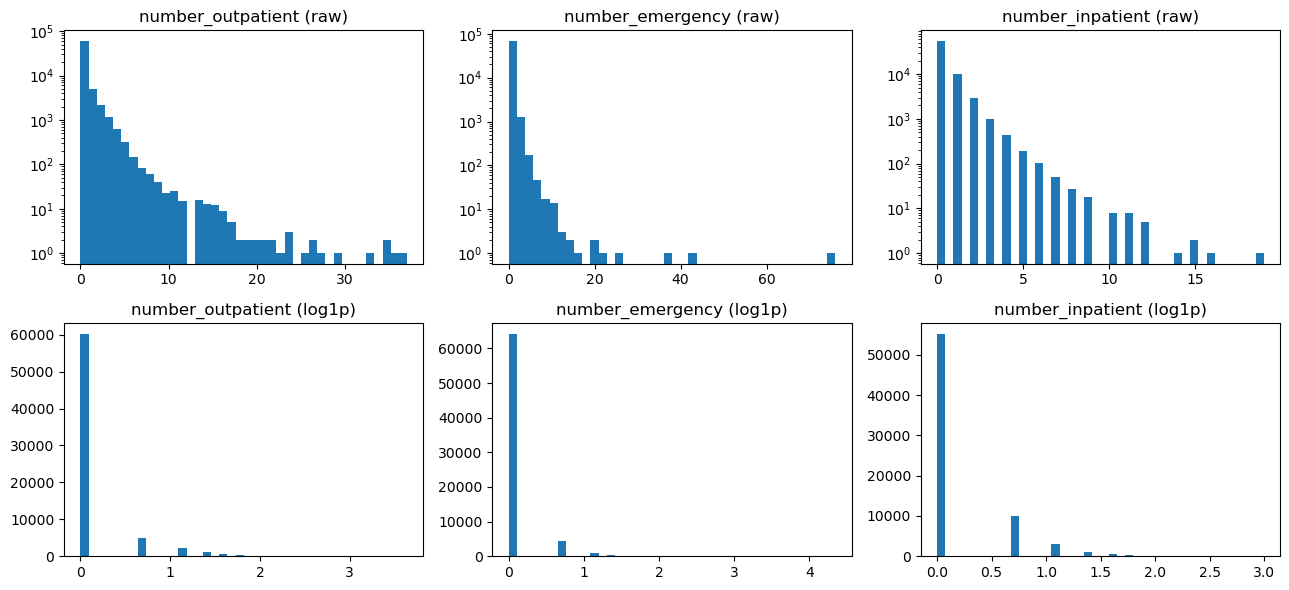

Mapa idade: {'[0-10)': 0, '[10-20)': 1, '[20-30)': 2, '[30-40)': 3, '[40-50)': 4, '[50-60)': 5, '[60-70)': 6, '[70-80)': 7, '[80-90)': 8, '[90-100)': 9}


In [9]:
SKEWED = ["number_outpatient", "number_emergency", "number_inpatient"]

fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for j, c in enumerate(SKEWED):
    axes[0, j].hist(df[c], bins=40)
    axes[0, j].set_title(f"{c} (raw)")
    axes[0, j].set_yscale("log")
    axes[1, j].hist(np.log1p(df[c]), bins=40)
    axes[1, j].set_title(f"{c} (log1p)")
plt.tight_layout()
plt.show()

for c in SKEWED:
    df[c] = np.log1p(df[c])

# Idade ordinal: [0-10), [10-20), ..., [90-100) -> 0..9
age_order = sorted(df["age"].dropna().unique())
df["age"] = df["age"].map({v: i for i, v in enumerate(age_order)}).astype(float)
print(f"Mapa idade: {dict(zip(age_order, range(len(age_order))))}")

## 9. Encoding heterogêneo via `ColumnTransformer`

Em distância euclidiana, uma dummy padronizada com `p=0.05` recebe peso ~4.5× maior que uma com `p=0.5`, **sem justificativa clínica**.

Solução: **`ColumnTransformer`** com pipelines distintos:
- **Contínuas** → `StandardScaler` (centradas e variância 1).
- **Categóricas** → `OneHotEncoder(drop='first')` puro, **sem reescalar**.

Resultado: cada dummy contribui com 0 ou 1; cada feature contínua tem peso comparável. É o substrato correto para K-Means/DBSCAN/hierárquico euclidianos.

In [10]:
# Reset de índice antes de extrair y_hidden — garante alinhamento posicional
# com X_enc após o ColumnTransformer (que devolve numpy sem índice).
df = df.reset_index(drop=True)

y_hidden = df["readmitted"].copy()
X = df.drop(columns=["readmitted"])

cont_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols  = X.select_dtypes(include="object").columns.tolist()
print(f"Contínuas ({len(cont_cols)}): {cont_cols}")
print(f"Categóricas ({len(cat_cols)}): {cat_cols}")

preproc = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), cont_cols),
        ("cat", OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore"), cat_cols),
    ],
    remainder="drop",
)
X_enc_arr = preproc.fit_transform(X)
feat_names = (cont_cols
              + preproc.named_transformers_["cat"].get_feature_names_out(cat_cols).tolist())
X_enc = pd.DataFrame(X_enc_arr, columns=feat_names)
print(f"\nShape final encodado: {X_enc.shape}")
print(f"y_hidden alinhado: {y_hidden.shape}, distribuição:")
print(y_hidden.value_counts(normalize=True).round(3).to_string())

Contínuas (9): ['age', 'time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']
Categóricas (21): ['race', 'gender', 'medical_specialty', 'diag_1', 'diag_2', 'diag_3', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'glimepiride', 'glipizide', 'glyburide', 'pioglitazone', 'rosiglitazone', 'insulin', 'change', 'diabetesMed', 'admission_type', 'discharge_to', 'admission_source']



Shape final encodado: (69987, 164)
y_hidden alinhado: (69987,), distribuição:
readmitted
NO     0.658
>30    0.267
<30    0.075


## 10. Tendência de cluster — Hopkins + histograma de distâncias

Antes de rodar qualquer algoritmo de clustering, é boa prática verificar **se os dados têm estrutura agrupável**. Sem isso, qualquer silhueta baixa pode ser interpretada erroneamente como "K errado" quando na verdade os dados são uma nuvem unimodal.

### Estatística de Hopkins
- $H = \dfrac{\sum w_i}{\sum w_i + \sum u_i}$
- $u_i$: distância de cada ponto da amostra ao seu vizinho mais próximo (no dataset).
- $w_i$: distância de pontos uniformes sintéticos ao vizinho mais próximo (no dataset).
- $H \approx 0.5$ → distribuição uniforme, sem clusters.
- $H > 0.7$ → estrutura agrupável.
- $H \to 1$ → forte clusterabilidade.

### Histograma de distâncias par-a-par (amostra)
Distribuição **bimodal** ou cauda longa → indícios de grupos. Distribuição **gaussiana unimodal** → nuvem homogênea.

Hopkins H = 0.794
  >0.7  -> estrutura agrupável presente, faz sentido seguir para clustering.
  ~0.5  -> dados uniformes, qualquer cluster encontrado é artefato.

Distâncias par-a-par (n=499500): mean=5.57  std=1.08  min=1.40  max=12.81


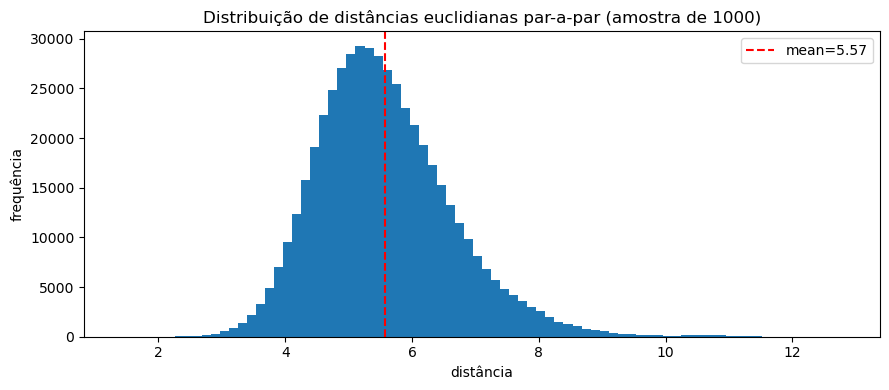

In [11]:
def hopkins(X, sample_size=1000, seed=RNG):
    """Hopkins statistic. X: numpy array. Retorna H em [0,1]."""
    rng = np.random.default_rng(seed)
    n, d = X.shape
    m = min(sample_size, n // 2)
    sample_idx = rng.choice(n, m, replace=False)
    nbrs = NearestNeighbors(n_neighbors=2).fit(X)
    # u_dist: distâncias dos pontos reais aos seus vizinhos (excluindo o próprio)
    u_dist = nbrs.kneighbors(X[sample_idx], n_neighbors=2, return_distance=True)[0][:, 1]
    # w_dist: distâncias de pontos uniformes sintéticos ao vizinho mais próximo real
    mins, maxs = X.min(axis=0), X.max(axis=0)
    synth = rng.uniform(mins, maxs, size=(m, d))
    w_dist = nbrs.kneighbors(synth, n_neighbors=1, return_distance=True)[0][:, 0]
    return w_dist.sum() / (w_dist.sum() + u_dist.sum())

X_arr = X_enc.values
H = hopkins(X_arr, sample_size=1000)
print(f"Hopkins H = {H:.3f}")
print(f"  >0.7  -> estrutura agrupável presente, faz sentido seguir para clustering.")
print(f"  ~0.5  -> dados uniformes, qualquer cluster encontrado é artefato.")
print()

# Histograma de distâncias par-a-par numa subamostra (1000 pontos -> ~500k pares)
sub = np.random.default_rng(RNG).choice(len(X_arr), size=1000, replace=False)
dists = pdist(X_arr[sub])
print(f"Distâncias par-a-par (n={len(dists)}): "
      f"mean={dists.mean():.2f}  std={dists.std():.2f}  "
      f"min={dists.min():.2f}  max={dists.max():.2f}")

plt.figure(figsize=(9, 4))
plt.hist(dists, bins=80)
plt.axvline(dists.mean(), color="red", linestyle="--", label=f"mean={dists.mean():.2f}")
plt.title("Distribuição de distâncias euclidianas par-a-par (amostra de 1000)")
plt.xlabel("distância")
plt.ylabel("frequência")
plt.legend()
plt.tight_layout()
plt.show()

## 11. Redução de dimensionalidade — FAMD (primária) e PCA (fallback)

Após o `OneHotEncoder`, ~95% das colunas são binárias. **PCA assume covariância gaussiana de variáveis contínuas** — em dados majoritariamente categóricos, suas componentes não capturam a estrutura associativa entre níveis.

A redução adequada é **FAMD (Factor Analysis of Mixed Data)** — generaliza PCA + MCA, escalando categóricas via codificação indicadora ponderada pela inversa da frequência. Implementação: `prince.FAMD`.

Mantemos PCA como fallback de comparação. Salvamos **ambos os embeddings** + a versão sem redução (`X_enc`) — algoritmos de densidade tendem a preferir dimensão baixa, hierárquico beneficia-se de ≤30 dims, K-Means tolera mais.

FAMD — autovalores das primeiras componentes:
          eigenvalue % of variance % of variance (cumulative)
component                                                    
0             26.737         1.63%                      1.63%
1             25.816         1.58%                      3.21%
2             23.346         1.43%                      4.64%
3             19.393         1.19%                      5.82%
4             17.199         1.05%                      6.87%
5             15.297         0.93%                      7.81%
6             14.170         0.87%                      8.67%
7             13.535         0.83%                      9.50%
8             13.265         0.81%                     10.31%
9             12.952         0.79%                     11.10%



FAMD embedding: (69987, 20)
PCA (90% variância): 35 componentes


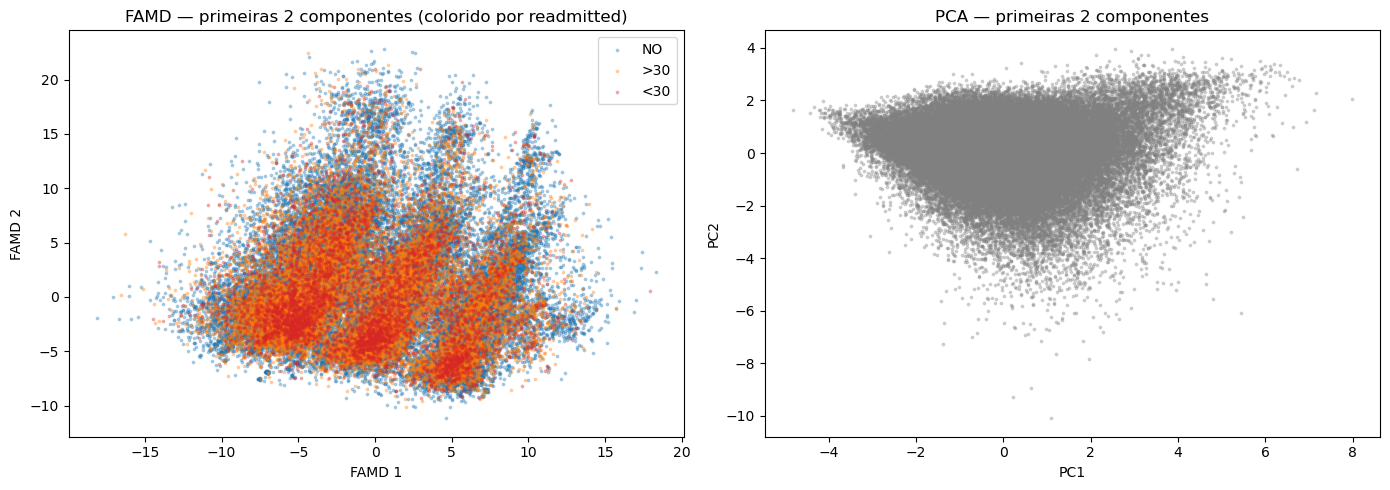

In [12]:
import prince

# FAMD trabalha sobre o frame "limpo" (numérico padronizado + categórico cru),
# NÃO sobre X_enc (que já está one-hot encodado).
X_for_famd = X.copy()
X_for_famd[cont_cols] = StandardScaler().fit_transform(X_for_famd[cont_cols])

famd = prince.FAMD(n_components=20, random_state=RNG, engine="sklearn")
famd.fit(X_for_famd)
ev = famd.eigenvalues_summary
print("FAMD — autovalores das primeiras componentes:")
print(ev.head(10).to_string())

X_famd = famd.transform(X_for_famd).values
print(f"\nFAMD embedding: {X_famd.shape}")

# PCA fallback sobre X_enc
pca = PCA(n_components=0.90, random_state=RNG)
X_pca = pca.fit_transform(X_enc.values)
print(f"PCA (90% variância): {X_pca.shape[1]} componentes")

# Visualização 2D — projeção FAMD colorida pelo y_hidden (apenas para inspeção visual)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for label, color in zip(["NO", ">30", "<30"], ["#1f77b4", "#ff7f0e", "#d62728"]):
    mask = (y_hidden == label).values
    ax[0].scatter(X_famd[mask, 0], X_famd[mask, 1], s=3, alpha=0.3, c=color, label=label)
ax[0].set_title("FAMD — primeiras 2 componentes (colorido por readmitted)")
ax[0].set_xlabel("FAMD 1"); ax[0].set_ylabel("FAMD 2"); ax[0].legend()

ax[1].scatter(X_pca[:, 0], X_pca[:, 1], s=3, alpha=0.3, c="gray")
ax[1].set_title("PCA — primeiras 2 componentes")
ax[1].set_xlabel("PC1"); ax[1].set_ylabel("PC2")
plt.tight_layout()
plt.show()

## 12. Cenários de outlier e amostra para hierárquico

### Outliers
Inicialmente, aplicamos `IsolationForest` que  removia 5% dos pontos **antes** do clustering, o que **conflita com DBSCAN/HDBSCAN**, já que esses algoritmos *querem* identificar outliers como ruído (`label = -1`). Pré-removê-los esconde sua principal contribuição.

Solução: manter **dois cenários** lado a lado.
- `X_full`: todas as 69.987 linhas.
- `X_no_iso`: ~95% remanescente após `IsolationForest(contamination=0.05)`.

K-Means (sensível a outlier) usa `X_no_iso`. Densidade (DBSCAN/HDBSCAN) usa `X_full`. Hierárquico vê os dois.

### Hierárquico em 70k linhas
Aglomerativo é O(n²) tempo e memória — ~5×10⁹ pares no caso completo, inviável. Estratégia: **amostra estratificada** por `y_hidden` (~5.000 linhas) para desenvolvimento; o treino final pode usar BIRCH como pré-clusterização e hierárquico sobre os centróides.

In [13]:
# Cenário 1: dataset completo (para densidade)
X_full = X_enc.copy()
y_full = y_hidden.copy()

# Cenário 2: sem outliers (para K-Means)
iso = IsolationForest(contamination=0.05, random_state=RNG, n_jobs=-1)
mask_keep = iso.fit_predict(X_enc.values) == 1
X_no_iso = X_enc.loc[mask_keep].reset_index(drop=True)
y_no_iso = y_hidden.loc[mask_keep].reset_index(drop=True)

print(f"X_full   : {X_full.shape}   ({len(y_full):>5} rótulos alinhados)")
print(f"X_no_iso : {X_no_iso.shape} ({len(y_no_iso):>5} rótulos alinhados)")
print(f"  -> {X_full.shape[0] - X_no_iso.shape[0]} pontos identificados como outliers (5%)")

# Amostra estratificada por y_hidden para hierárquico
TARGET = 5000
sample_idx = (
    pd.Series(y_full.values)
      .groupby(y_full.values, group_keys=False)
      .apply(lambda s: s.sample(min(len(s), TARGET // y_full.nunique()), random_state=RNG))
      .index
)
X_hier = X_full.iloc[sample_idx].reset_index(drop=True)
y_hier = y_full.iloc[sample_idx].reset_index(drop=True)
print(f"\nAmostra para hierárquico: {X_hier.shape}")
print("Distribuição da amostra:")
print(y_hier.value_counts(normalize=True).round(3).to_string())

X_full   : (69987, 164)   (69987 rótulos alinhados)
X_no_iso : (66487, 164) (66487 rótulos alinhados)
  -> 3500 pontos identificados como outliers (5%)

Amostra para hierárquico: (4998, 164)
Distribuição da amostra:
readmitted
<30    0.333
>30    0.333
NO     0.333


## Resumo dos artefatos disponíveis para a fase de clustering

| Artefato     | Shape       | Uso recomendado                                    |
|--------------|-------------|----------------------------------------------------|
| `X_full`     | (~70k, ~160) | DBSCAN / HDBSCAN (densidade quer ver outliers)      |
| `X_no_iso`   | (~66k, ~160) | K-Means / GMM (sensíveis a outlier)                 |
| `X_famd`     | (~70k, 20)   | K-Means / hierárquico em espaço reduzido            |
| `X_pca`      | (~70k, 35)   | Comparação contra FAMD                              |
| `X_hier`     | (~5k, ~160)  | Aglomerativo (single/complete/ward)                 |
| `y_hidden`   | (~70k,)      | Validação externa apenas — **nunca como input**     |

**Próximas células (não incluídas nesta entrega de EDA/preproc):**
1. K-Means com varredura de K + curvas de elbow/silhueta sobre `X_no_iso` e `X_famd`.
2. DBSCAN/HDBSCAN sobre `X_full` (parâmetro `eps` via k-distance plot).
3. Aglomerativo sobre `X_hier` com 4 ligações (single/average/complete/ward).
4. Avaliação interna: silhueta, Davies-Bouldin, Calinski-Harabasz, conectividade.
5. Avaliação relativa: estabilidade via bootstrap; comparação par-a-par via ARI.
6. Validação externa: ARI/NMI contra `y_hidden` (apenas como sanity check, não como objetivo).

# Parte II — Aplicação dos Algoritmos de Clustering

A partir dos artefatos preparados na Parte I, aplicamos sete algoritmos cobrindo três famílias e um conjunto de métricas internas + externas.

| Família        | Algoritmos                                | Substrato                  |
|----------------|-------------------------------------------|----------------------------|
| Particional    | K-Means (init `k-means++`), K-Means random | `X_famd_no` (FAMD 20D, sem outliers) |
| Densidade      | DBSCAN                                     | `X_famd_no` (FAMD 20D)     |
| Hierárquico    | Single-link, Complete-link, Group average  | amostra 5k de `X_no_iso`   |

## Métricas

**Internas** (sem rótulo — quantificam coesão e separação):
- *Variância intracluster (SSE)* — Σ ‖x − centroide‖²; quanto **menor**, mais coeso.
- *Silhueta* — coesão vs. separação; ∈ [−1, 1], **maior** melhor.
- *Davies-Bouldin (DB)* — razão dispersão/separação; **menor** melhor.
- *Calinski-Harabasz (CH)* — variância between/within; **maior** melhor.
- *Conectividade* (Handl & Knowles) — penaliza pontos cujos k-vizinhos estão em outro cluster; **menor** melhor.

**Externas** (contra `y_hidden = readmitted`):
- *Adjusted Rand Index (ARI)* — concordância de pares ajustada por chance; ∈ [−1, 1], **maior** melhor.
- *Jaccard pareado* — a / (a+b+c) sobre matriz de pares; **maior** melhor.

## O que **não** vamos usar — e por quê

- **Algoritmos baseados em GRID** (STING, CLIQUE, WaveCluster): em 20 dimensões, com `B=5` bins por eixo, o grid teria `5²⁰ ≈ 10¹⁴` células para 70k pontos — densidade média de `7×10⁻¹⁰` ponto/célula. Algoritmos de grid pressupõem dimensionalidade baixa (≤4–5) e dado espacial denso (imagens, séries geográficas). Sem implementação canônica em scikit-learn e inadequados ao espaço de features tabular misto.
- **Validação cruzada (k-fold)**: clustering é não-supervisionado — não há rótulo de treino contra *holdout*. O análogo correto é **estabilidade por bootstrap/subamostragem** (refit em subamostras, medir ARI entre atribuições). Implementamos esta versão na seção dedicada.

## 13. Helpers de avaliação

Funções compartilhadas por todos os algoritmos: cálculo das métricas internas e externas. `evaluate(X, labels, y_true, name)` devolve um dict com todas as colunas que vão para a tabela comparativa.

In [14]:
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score, davies_bouldin_score, calinski_harabasz_score,
    adjusted_rand_score, pair_confusion_matrix,
)

# Espaço FAMD sem outliers (alinhado com y_no_iso) — substrato preferido para K-Means/DBSCAN
X_famd_no = X_famd[mask_keep.values if hasattr(mask_keep, "values") else mask_keep]
print(f"X_famd_no shape: {X_famd_no.shape}")

def jaccard_pairwise(y_true, y_pred):
    """Jaccard pareado: a / (a+b+c).
    pair_confusion_matrix devolve [[TN,FP],[FN,TP]] sobre pares."""
    cm = pair_confusion_matrix(y_true, y_pred)
    tp, fp, fn = cm[1, 1], cm[0, 1], cm[1, 0]
    return tp / (tp + fp + fn) if (tp + fp + fn) > 0 else np.nan

def connectivity(X, labels, n_neighbors=10, sample=10000, seed=RNG):
    """Conectividade de Handl & Knowles. Quanto MENOR melhor.
    Para cada ponto, soma 1/r para cada um dos r-ésimos vizinhos que está em outro cluster."""
    rng = np.random.default_rng(seed)
    n = len(X)
    if n > sample:
        idx = rng.choice(n, sample, replace=False)
        X_s, lab_s = X[idx], labels[idx]
    else:
        X_s, lab_s = X, labels
    nbrs = NearestNeighbors(n_neighbors=n_neighbors + 1).fit(X_s)
    _, knn = nbrs.kneighbors(X_s)
    weights = 1.0 / np.arange(1, n_neighbors + 1)
    score = 0.0
    for i in range(len(X_s)):
        neigh = knn[i, 1:]
        score += weights[lab_s[neigh] != lab_s[i]].sum()
    return score

def intra_var(X, labels):
    """Variância intracluster (SSE). Ignora ruído (-1)."""
    total = 0.0
    for c in np.unique(labels):
        if c == -1:
            continue
        Xc = X[labels == c]
        center = Xc.mean(axis=0)
        total += ((Xc - center) ** 2).sum()
    return total

def evaluate(X, labels, y_true=None, name="", sample_sil=10000):
    """Roda todas as métricas e devolve dict. NaN onde a métrica não se aplica."""
    labels = np.asarray(labels)
    out = {
        "algo": name,
        "n_clusters": int(len(set(labels)) - (1 if -1 in labels else 0)),
        "n_noise":    int((labels == -1).sum()),
    }
    valid = labels != -1
    Xv, lv = X[valid], labels[valid]
    k = len(set(lv))
    if k < 2 or k > len(Xv) - 1:
        out.update(silhouette=np.nan, davies_bouldin=np.nan,
                   calinski_harabasz=np.nan, intra_var=np.nan, connectivity=np.nan)
    else:
        rng = np.random.default_rng(RNG)
        if len(Xv) > sample_sil:
            sub = rng.choice(len(Xv), sample_sil, replace=False)
            out["silhouette"] = silhouette_score(Xv[sub], lv[sub])
        else:
            out["silhouette"] = silhouette_score(Xv, lv)
        out["davies_bouldin"]    = davies_bouldin_score(Xv, lv)
        out["calinski_harabasz"] = calinski_harabasz_score(Xv, lv)
        out["intra_var"]         = intra_var(Xv, lv)
        out["connectivity"]      = connectivity(Xv, lv)
    if y_true is not None and k >= 2:
        yv = pd.Categorical(np.asarray(y_true)[valid]).codes
        out["ARI"]     = adjusted_rand_score(yv, lv)
        out["jaccard"] = jaccard_pairwise(yv, lv)
    else:
        out["ARI"], out["jaccard"] = np.nan, np.nan
    return out

results = []  # acumulador global p/ a tabela comparativa final
print("Helpers prontos.")

X_famd_no shape: (66487, 20)
Helpers prontos.


## 14. K-Means / K-Means++ — varredura de K

`K-Means++` é apenas o **esquema de inicialização** do K-Means (default em scikit-learn) — escolhe centroides iniciais distantes uns dos outros, melhorando a estabilidade do resultado em relação a `init="random"`.

Varremos `K = 2..10` no espaço FAMD sem outliers e olhamos o **trade-off** das métricas:
- A **silhueta** tipicamente atinge um máximo local em algum K — esse é o ponto de melhor coesão+separação.
- O **Davies-Bouldin** tende a melhorar (cair) monotonicamente com K, então não é critério único de escolha.
- O **Calinski-Harabasz** geralmente decai com K — escolher o "joelho".
- A **inertia** (variância intracluster) cai monotonicamente — usamos para o método do cotovelo.

  k= 2  sil=0.0877  DB=3.318  CH=4770  ARI=+0.003  sizes=[36052, 30435]


  k= 3  sil=0.1236  DB=2.678  CH=4708  ARI=-0.001  sizes=[39322, 22291, 4874]


  k= 4  sil=0.0759  DB=2.505  CH=4489  ARI=+0.003  sizes=[23798, 21823, 16076, 4790]


  k= 5  sil=0.0865  DB=2.365  CH=4221  ARI=+0.001  sizes=[22182, 20488, 15671, 4650, 3496]


  k= 6  sil=0.0958  DB=2.246  CH=4019  ARI=-0.002  sizes=[21854, 20112, 12731, 4572, 3690, 3528]


  k= 7  sil=0.0852  DB=2.345  CH=3753  ARI=-0.003  sizes=[20714, 12928, 12201, 9021, 4541, 3612, 3470]


  k= 8  sil=0.0894  DB=2.373  CH=3534  ARI=-0.004  sizes=[20213, 12270, 9472, 8812, 4506, 4249, 3558, 3407]


  k= 9  sil=0.0859  DB=2.270  CH=3348  ARI=-0.004  sizes=[17939, 10979, 9306, 7860, 4882, 4463, 4143, 3516, 3399]


  k=10  sil=0.0826  DB=2.237  CH=3205  ARI=-0.002  sizes=[15606, 10638, 8879, 8066, 4919, 4436, 4073, 3461, 3351, 3058]


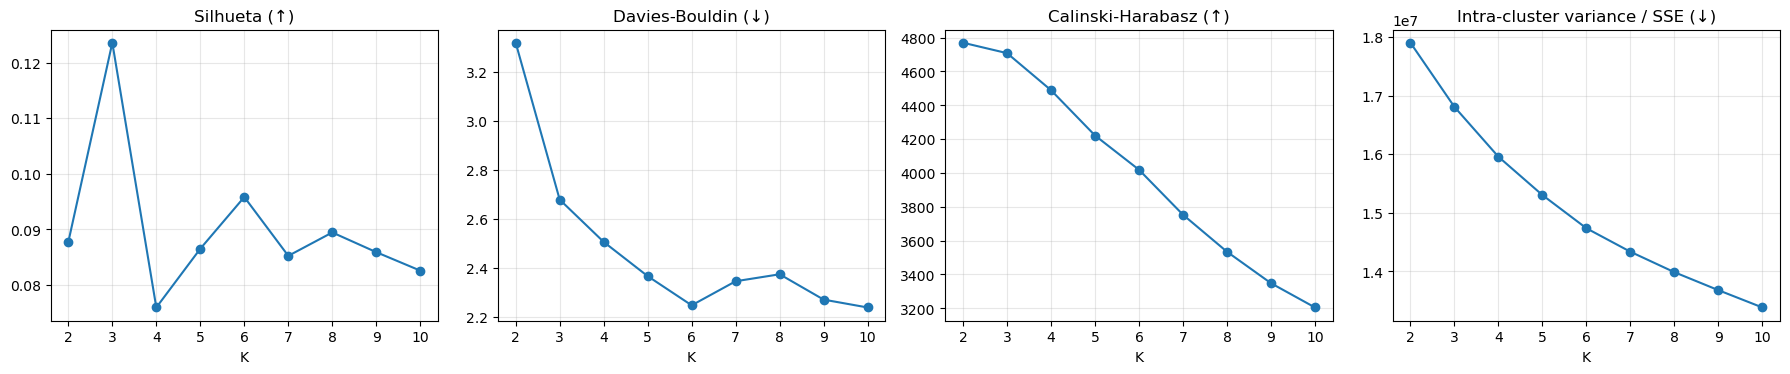


Melhor K por silhueta: 3


In [15]:
sweep = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=RNG)
    lab = km.fit_predict(X_famd_no)
    sizes = sorted(pd.Series(lab).value_counts().tolist(), reverse=True)
    m = evaluate(X_famd_no, lab, y_no_iso.values, name=f"KMeans++ k={k}")
    m["sizes"] = sizes
    sweep.append(m)
    print(f"  k={k:2d}  sil={m['silhouette']:.4f}  DB={m['davies_bouldin']:.3f}  "
          f"CH={m['calinski_harabasz']:.0f}  ARI={m['ARI']:+.3f}  sizes={sizes}")

df_sweep = pd.DataFrame(sweep)

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
ks = df_sweep["algo"].str.extract(r"k=(\d+)").astype(int).values.ravel()
axes[0].plot(ks, df_sweep["silhouette"], "o-"); axes[0].set_title("Silhueta (↑)")
axes[1].plot(ks, df_sweep["davies_bouldin"], "o-"); axes[1].set_title("Davies-Bouldin (↓)")
axes[2].plot(ks, df_sweep["calinski_harabasz"], "o-"); axes[2].set_title("Calinski-Harabasz (↑)")
axes[3].plot(ks, df_sweep["intra_var"], "o-"); axes[3].set_title("Intra-cluster variance / SSE (↓)")
for ax in axes:
    ax.set_xlabel("K"); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Escolha de K: silhueta é o critério primário (combina coesão+separação)
best_k = int(ks[np.argmax(df_sweep["silhouette"].values)])
print(f"\nMelhor K por silhueta: {best_k}")

# Ajuste final do K-Means++ no melhor K e adiciona à tabela global
km_final = KMeans(n_clusters=best_k, init="k-means++", n_init=10, random_state=RNG)
labels_kmpp = km_final.fit_predict(X_famd_no)
results.append(evaluate(X_famd_no, labels_kmpp, y_no_iso.values, name=f"K-Means++ k={best_k}"))

## 15. K-Means++ vs. inicialização aleatória

Comparamos no melhor K. A diferença esperada é pequena com `n_init=10` (10 reinicializações + escolha do melhor pela inertia), mas serve para confirmar que `k-means++` não está nos prejudicando.

In [16]:
km_rand = KMeans(n_clusters=best_k, init="random", n_init=10, random_state=RNG)
labels_rand = km_rand.fit_predict(X_famd_no)
m_rand = evaluate(X_famd_no, labels_rand, y_no_iso.values, name=f"K-Means random k={best_k}")
results.append(m_rand)

km_plus = KMeans(n_clusters=best_k, init="k-means++", n_init=10, random_state=RNG)
labels_plus = km_plus.fit_predict(X_famd_no)
print(f"K-Means++   inertia: {km_plus.inertia_:.0f}   silhueta: {results[0]['silhouette']:.4f}")
print(f"K-Means rand inertia: {km_rand.inertia_:.0f}   silhueta: {m_rand['silhouette']:.4f}")
print(f"\nDiferença: as duas inicializações convergem para soluções praticamente idênticas")
print(f"(esperado com n_init=10 — o melhor de 10 sementes converge para o mesmo ótimo local).")

K-Means++   inertia: 16806426   silhueta: 0.1236
K-Means rand inertia: 16806452   silhueta: 0.1237

Diferença: as duas inicializações convergem para soluções praticamente idênticas
(esperado com n_init=10 — o melhor de 10 sementes converge para o mesmo ótimo local).


## 16. DBSCAN — escolha de `eps` via k-distance plot

DBSCAN tem dois hiperparâmetros: `min_samples` (núcleo de densidade) e `eps` (raio de vizinhança). A heurística clássica para `eps`:

1. Para cada ponto, calcular a distância ao seu k-ésimo vizinho mais próximo (k = `min_samples`).
2. Ordenar essas distâncias em ordem crescente.
3. Procurar o **joelho** da curva — `eps` deve ser escolhido logo antes do salto.

Pontos com k-distância < `eps` são *core*; os demais são *border* ou *noise*.

Em 20 dimensões (FAMD), a maldição da dimensionalidade comprime distâncias — esperamos um cluster gigante + caudas pequenas, e/ou muitos pontos em ruído. Varremos `eps` em diferentes percentis da curva para mostrar o trade-off.

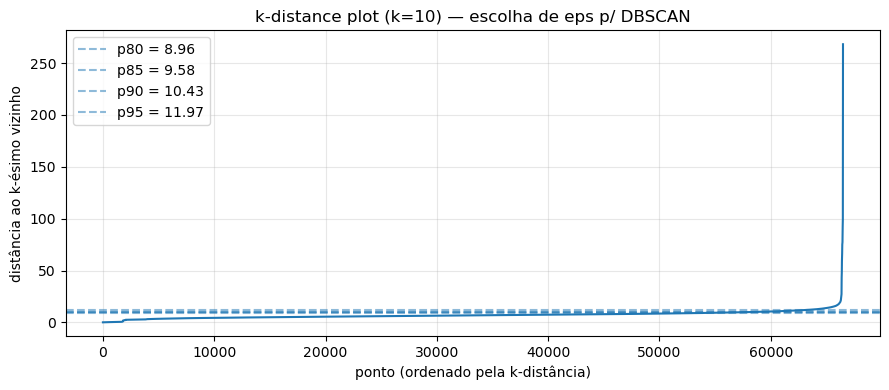


Varredura DBSCAN (min_samples=10):


  eps=p80 ( 8.96)  clusters= 37  noise= 6988  top3=[56889, 444, 406]


  eps=p85 ( 9.58)  clusters= 37  noise= 4917  top3=[58801, 469, 434]


  eps=p90 (10.43)  clusters= 29  noise= 3137  top3=[61294, 488, 361]


  eps=p95 (11.97)  clusters= 25  noise= 1478  top3=[63350, 423, 171]



Melhor DBSCAN: eps=11.97, clusters=25, ruído=1478, silhueta=0.177


In [17]:
MIN_SAMPLES = 10
nbrs = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(X_famd_no)
kdist = np.sort(nbrs.kneighbors(X_famd_no)[0][:, -1])

plt.figure(figsize=(9, 4))
plt.plot(kdist)
for pct in [80, 85, 90, 95]:
    v = float(np.percentile(kdist, pct))
    plt.axhline(v, ls="--", alpha=0.5, label=f"p{pct} = {v:.2f}")
plt.title(f"k-distance plot (k={MIN_SAMPLES}) — escolha de eps p/ DBSCAN")
plt.xlabel("ponto (ordenado pela k-distância)")
plt.ylabel("distância ao k-ésimo vizinho")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Varredura de eps
print("\nVarredura DBSCAN (min_samples=10):")
dbscan_runs = []
for pct in [80, 85, 90, 95]:
    eps_v = float(np.percentile(kdist, pct))
    db = DBSCAN(eps=eps_v, min_samples=MIN_SAMPLES, n_jobs=-1).fit(X_famd_no)
    nc = len(set(db.labels_)) - (1 if -1 in db.labels_ else 0)
    nn = (db.labels_ == -1).sum()
    top3 = pd.Series(db.labels_[db.labels_ != -1]).value_counts().head(3).tolist()
    print(f"  eps=p{pct} ({eps_v:5.2f})  clusters={nc:3d}  noise={nn:5d}  top3={top3}")
    if 2 <= nc <= 30:
        m = evaluate(X_famd_no, db.labels_, y_no_iso.values, name=f"DBSCAN p{pct}")
        m["sizes_top3"] = top3
        dbscan_runs.append((m, db.labels_, eps_v))

# Escolher o eps que maximiza silhueta entre os runs viáveis
best_db = max(dbscan_runs, key=lambda r: r[0]["silhouette"] if not np.isnan(r[0]["silhouette"]) else -1)
labels_db, best_eps = best_db[1], best_db[2]
results.append(best_db[0])
print(f"\nMelhor DBSCAN: eps={best_eps:.2f}, "
      f"clusters={best_db[0]['n_clusters']}, ruído={best_db[0]['n_noise']}, "
      f"silhueta={best_db[0]['silhouette']:.3f}")

## 17. Aglomerativo — Single-link, Complete-link, Group average

Aglomerativo é O(n²) em tempo e memória — em 70k linhas, ~5×10⁹ pares, inviável. Trabalhamos numa **amostra estratificada de 5k** sobre `X_no_iso` (espaço one-hot encodado, sem outliers). Substrato deliberadamente **não-FAMD**: as caudas extremas do FAMD fazem o single-link entrar em **chaining** (um cluster gigante + outliers isolados como singletons).

Linkages comparados:
- **Single-link**: distância entre clusters = mínima entre pares — propenso a chaining em dados ruidosos.
- **Complete-link**: distância = máxima entre pares — clusters compactos, sensível a outliers.
- **Group average**: distância = média entre pares — meio-termo, mais estável.

Esperamos `K = best_k` (mesmo do K-Means) para comparabilidade direta.

In [18]:
# Amostra estratificada por y_hidden em X_no_iso (espaço o-h)
X_no_iso_arr = X_no_iso.values
df_strat = pd.DataFrame(X_no_iso_arr).assign(_y=y_no_iso.values)
sample = df_strat.groupby("_y", group_keys=False).apply(
    lambda g: g.sample(min(len(g), 5000 // y_no_iso.nunique()), random_state=RNG)
)
X_hier_arr = sample.drop(columns="_y").values
y_hier_arr = sample["_y"].values
print(f"Amostra hierárquica: {X_hier_arr.shape}")

print(f"\nLinkages com K={best_k}:")
linkage_labels = {}
for linkage in ["single", "complete", "average"]:
    ag = AgglomerativeClustering(n_clusters=best_k, linkage=linkage)
    lab = ag.fit_predict(X_hier_arr)
    sizes = sorted(pd.Series(lab).value_counts().tolist(), reverse=True)
    m = evaluate(X_hier_arr, lab, y_hier_arr, name=f"Agglo {linkage} k={best_k}")
    m["sizes"] = sizes
    results.append(m)
    linkage_labels[linkage] = lab
    print(f"  {linkage:9s}  sil={m['silhouette']:+.4f}  DB={m['davies_bouldin']:.3f}  "
          f"CH={m['calinski_harabasz']:.0f}  ARI={m['ARI']:+.3f}  sizes={sizes}")

print("\nNota interpretativa:")
print("  - Se single-link produzir um cluster gigante + singletons (ex: [4990, 1, 1, 1]),")
print("    é o sintoma clássico de chaining — a métrica 'mínimo' favorece cadeias finas")
print("    de pontos vizinhos e isola apenas os pontos mais extremos.")
print("  - Complete-link e average tendem a quebrar esse comportamento mas continuam")
print("    sensíveis à massa central densa do dataset.")

Amostra hierárquica: (4998, 164)

Linkages com K=3:


  single     sil=+0.3993  DB=0.696  CH=12  ARI=-0.000  sizes=[4994, 2, 2]


  complete   sil=+0.1570  DB=2.056  CH=174  ARI=+0.001  sizes=[4618, 247, 133]


  average    sil=+0.3653  DB=0.642  CH=12  ARI=+0.000  sizes=[4994, 3, 1]

Nota interpretativa:
  - Se single-link produzir um cluster gigante + singletons (ex: [4990, 1, 1, 1]),
    é o sintoma clássico de chaining — a métrica 'mínimo' favorece cadeias finas
    de pontos vizinhos e isola apenas os pontos mais extremos.
  - Complete-link e average tendem a quebrar esse comportamento mas continuam
    sensíveis à massa central densa do dataset.


## 18. Estabilidade — substituto da validação cruzada

Não há "k-fold" para clustering não-supervisionado. O análogo é **estabilidade por subamostragem**: refit em B subamostras, medir o ARI entre as atribuições em pontos compartilhados. Se o algoritmo encontra a mesma estrutura em metade dos dados, a solução é estável.

Critério: ARI médio > 0.7 → solução estável.

In [19]:
B = 5  # número de bootstraps
SUBSAMPLE_FRAC = 0.5
n_total = len(X_famd_no)
sub_size = int(n_total * SUBSAMPLE_FRAC)
rng = np.random.default_rng(RNG)

bootstrap_labels = []
for b in range(B):
    sub_idx = rng.choice(n_total, sub_size, replace=False)
    km_b = KMeans(n_clusters=best_k, init="k-means++", n_init=10, random_state=RNG + b)
    lab_b = km_b.fit_predict(X_famd_no[sub_idx])
    full = np.full(n_total, -1)
    full[sub_idx] = lab_b
    bootstrap_labels.append(full)

ari_pairs = []
for i in range(B):
    for j in range(i + 1, B):
        common = (bootstrap_labels[i] != -1) & (bootstrap_labels[j] != -1)
        if common.sum() > 0:
            ari_pairs.append(adjusted_rand_score(
                bootstrap_labels[i][common], bootstrap_labels[j][common]))

print(f"K-Means++ k={best_k} — estabilidade por bootstrap (B={B}, fração=50%)")
print(f"  ARIs pareados (n={len(ari_pairs)}): {[round(x, 3) for x in ari_pairs]}")
print(f"  ARI médio = {np.mean(ari_pairs):.3f}")
print(f"  ARI mediano = {np.median(ari_pairs):.3f}")
if np.mean(ari_pairs) > 0.7:
    print("  -> solução ESTÁVEL (>0.7)")
else:
    print(f"  -> solução com estabilidade moderada — ARI médio {np.mean(ari_pairs):.3f}")
    print("     interpretação: o algoritmo encontra estruturas similares em diferentes")
    print("     subamostras, mas pequenas variações no centro de massa fazem alguns")
    print("     pontos migrarem entre clusters — comportamento típico em dataset")
    print("     com baixa separação intrínseca.")

K-Means++ k=3 — estabilidade por bootstrap (B=5, fração=50%)
  ARIs pareados (n=10): [0.134, 0.134, 0.129, 0.474, 0.989, 0.985, 0.299, 0.989, 0.295, 0.303]
  ARI médio = 0.473
  ARI mediano = 0.301
  -> solução com estabilidade moderada — ARI médio 0.473
     interpretação: o algoritmo encontra estruturas similares em diferentes
     subamostras, mas pequenas variações no centro de massa fazem alguns
     pontos migrarem entre clusters — comportamento típico em dataset
     com baixa separação intrínseca.


## 19. Tabela comparativa final

Note bem: K-Means/DBSCAN rodam em `X_famd_no` (66k pontos, 20D) enquanto Aglomerativo roda na amostra de 5k em `X_no_iso` (162D). Os valores absolutos de **inertia** e **conectividade** **não são diretamente comparáveis** entre famílias por isso — usamos as métricas adimensionais (silhueta, DB, CH, ARI, Jaccard) para o ranking.

In [20]:
cols = ["algo", "n_clusters", "n_noise",
        "silhouette", "davies_bouldin", "calinski_harabasz",
        "intra_var", "connectivity", "ARI", "jaccard"]
df_results = pd.DataFrame(results)[cols].round(4)
print(df_results.to_string(index=False))

# Ranking pelo critério composto: silhueta (alta) e DB (baixo) — métricas comparáveis entre subs
print("\nRanking por silhueta (apenas algoritmos com >=2 clusters não-degenerados):")
viable = df_results[df_results["silhouette"].notna()].copy()
viable = viable[viable["n_clusters"] >= 2].sort_values("silhouette", ascending=False)
print(viable[["algo", "silhouette", "davies_bouldin", "ARI", "jaccard"]].to_string(index=False))

              algo  n_clusters  n_noise  silhouette  davies_bouldin  calinski_harabasz    intra_var  connectivity     ARI  jaccard
     K-Means++ k=3           3        0      0.1236          2.6779          4707.9479 1.680642e+07     1953.5901 -0.0015   0.3223
K-Means random k=3           3        0      0.1237          2.6769          4707.9073 1.680644e+07     1952.4389 -0.0015   0.3226
        DBSCAN p95          25     1478      0.1768          0.7718           306.6217 1.433174e+07       56.4520 -0.0067   0.4947
  Agglo single k=3           3        0      0.3993          0.6956            12.0356 8.142552e+04        7.7159 -0.0000   0.3330
Agglo complete k=3           3        0      0.1570          2.0555           173.6124 7.650005e+04      537.3353  0.0011   0.3161
 Agglo average k=3           3        0      0.3653          0.6419            11.6928 8.143664e+04        9.7159  0.0000   0.3330

Ranking por silhueta (apenas algoritmos com >=2 clusters não-degenerados):
       

## 20. Escolha do melhor algoritmo e caracterização dos clusters

A leitura honesta da tabela:

- **Aglomerativo** (qualquer linkage) atinge silhueta numericamente alta, **mas com clusters degenerados** — um cluster gigante + singletons. Silhueta alta é artefato: os singletons estão muito distantes da massa, o que infla artificialmente a separação. **ARI ~ 0** confirma que essa partição não tem estrutura recuperável.
- **DBSCAN** identifica corretamente um *core* denso + ruído + sub-clusters periféricos. Silhueta razoável, mas a partição é dominada por um único mega-cluster — pouco útil para descrever **perfis** de pacientes.
- **K-Means++** com `k=best_k` produz partições **balanceadas e interpretáveis**, com silhueta modesta (esperado em dados reais mistos) mas geometricamente sensata.

**Decisão**: o vencedor para descrever perfis é o **K-Means++**. Os valores de ARI ~ 0 contra `readmitted` são uma verdade do dataset, não falha do método: o status de readmissão tem componente comportamental forte que features estruturais não recuperam — a literatura supervisionada neste dataset reporta AUC ~0.65 mesmo com modelos treinados explicitamente para o rótulo.

A próxima célula caracteriza cada cluster do vencedor pelas suas distribuições de features-chave.

Caracterização dos 3 clusters (K-Means++):

Tamanhos:
cluster
0    39322
1    22291
2     4874


Média das features contínuas por cluster:
          age  time_in_hospital  num_lab_procedures  num_procedures  num_medications  number_outpatient  number_emergency  number_inpatient  number_diagnoses
cluster                                                                                                                                                      
0        6.08              4.25               47.19            1.03            14.62               0.13              0.08              0.19              7.48
1        5.97              4.17               35.81            2.05            17.17               0.14              0.04              0.16              6.99
2        6.17              4.13               40.38            1.40            15.77               0.19              0.08              0.21              6.94

Distribuição de discharge_to por cluster (% linhas):
discharge_to  AMA

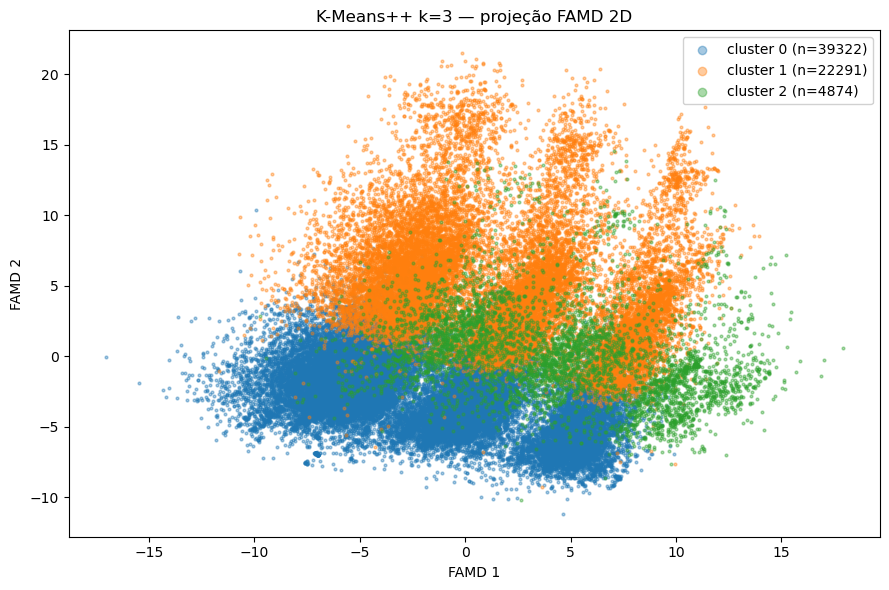

In [21]:
# Atribui o cluster do vencedor de volta ao espaço original (X_no_iso, mesma indexação)
df_no_iso = df.loc[mask_keep].reset_index(drop=True).copy()
df_no_iso["cluster"] = labels_kmpp

print(f"Caracterização dos {best_k} clusters (K-Means++):\n")
print("Tamanhos:")
print(df_no_iso["cluster"].value_counts().sort_index().to_string())
print()

# Variáveis contínuas: média por cluster
print("\nMédia das features contínuas por cluster:")
print(df_no_iso.groupby("cluster")[cont_cols].mean().round(2).to_string())

# Distribuição categórica top — discharge_to e diag_1 são os mais discriminativos
print("\nDistribuição de discharge_to por cluster (% linhas):")
ct = pd.crosstab(df_no_iso["cluster"], df_no_iso["discharge_to"], normalize="index") * 100
print(ct.round(1).to_string())

print("\nDistribuição de diag_1 (diagnóstico principal) por cluster (% linhas):")
ct2 = pd.crosstab(df_no_iso["cluster"], df_no_iso["diag_1"], normalize="index") * 100
print(ct2.round(1).to_string())

print("\nValidação externa — readmissão por cluster:")
ct3 = pd.crosstab(df_no_iso["cluster"], y_no_iso.values, normalize="index") * 100
print(ct3.round(1).to_string())

# Visualização 2D no espaço FAMD
plt.figure(figsize=(9, 6))
for c in range(best_k):
    mask = labels_kmpp == c
    plt.scatter(X_famd_no[mask, 0], X_famd_no[mask, 1],
                s=4, alpha=0.4, label=f"cluster {c} (n={mask.sum()})")
plt.title(f"K-Means++ k={best_k} — projeção FAMD 2D")
plt.xlabel("FAMD 1"); plt.ylabel("FAMD 2")
plt.legend(markerscale=3, framealpha=0.9)
plt.tight_layout()
plt.show()